# 📘 Lasso Regression in Machine Learning

## 📖 Introduction
Lasso Regression (Least Absolute Shrinkage and Selection Operator) is a linear regression technique that uses L1 regularization to prevent overfitting and improve model accuracy. It adds a penalty equivalent to the sum of the absolute values of the coefficients to the loss function, forcing less important feature coefficients to exactly zero, thus performing automatic feature selection.

Cost:
RSS + λ Σ|bj|

## ❓ Detailed Information
- Shrinks coefficients
- Can force some coefficients to zero
- Performs automatic feature selection

## ⚙️ Working
1. Fit regression
2. Add L1 penalty
3. Penalize coefficients
4. Push weak coefficients to zero

## ✅ Advantages
- Prevents overfitting
- Feature selection
- Simpler models

## ❌ Disadvantages
- Needs alpha tuning
- Can remove useful variables

## 🌍 Applications
- Genomics
- Finance
- Text classification


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression,Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

np.random.seed(0)
X=np.sort(np.random.rand(40)).reshape(-1,1)
y=np.sin(2*np.pi*X).ravel()+np.random.randn(40)*0.2
X_plot=np.linspace(0,1,200).reshape(-1,1)


## Graph: Linear vs Lasso

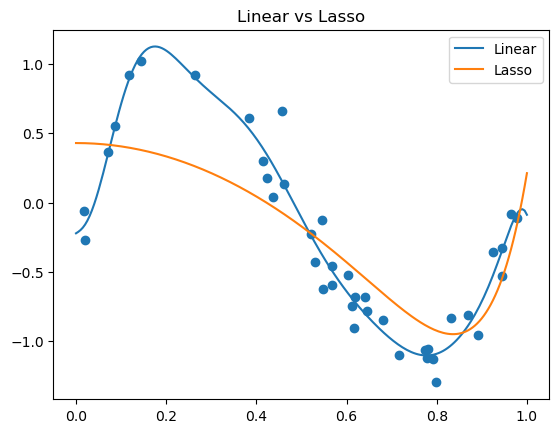

In [2]:
linear=make_pipeline(
PolynomialFeatures(12),
LinearRegression()
)

lasso=make_pipeline(
PolynomialFeatures(12),
Lasso(alpha=0.01,max_iter=10000)
)

linear.fit(X,y)
lasso.fit(X,y)

plt.figure()
plt.scatter(X,y)
plt.plot(X_plot,linear.predict(X_plot),label='Linear')
plt.plot(X_plot,lasso.predict(X_plot),label='Lasso')
plt.legend()
plt.title("Linear vs Lasso")
plt.show()


## Graph: Lambda Effect

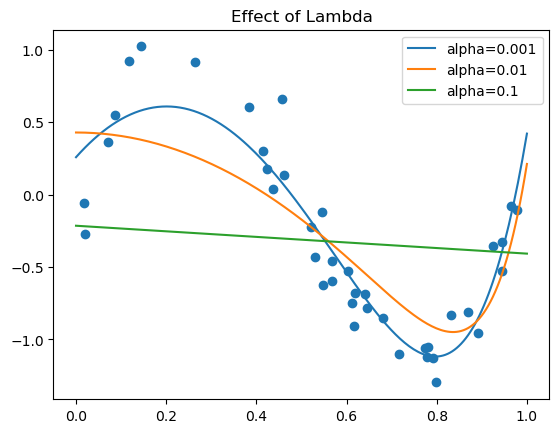

In [3]:
alphas=[0.001,0.01,0.1]

plt.figure()
plt.scatter(X,y)

for a in alphas:
    model=make_pipeline(
        PolynomialFeatures(12),
        Lasso(alpha=a,max_iter=10000)
    )
    model.fit(X,y)
    plt.plot(X_plot,model.predict(X_plot),label=f'alpha={a}')

plt.legend()
plt.title("Effect of Lambda")
plt.show()


## Feature Selection Demo

In [4]:
X2=np.random.randn(100,5)
y2=3*X2[:,0]+2*X2[:,1]+np.random.randn(100)

model=Lasso(alpha=0.1)
model.fit(X2,y2)

print("Coefficients:")
print(model.coef_)


Coefficients:
[ 2.921533    1.89194272 -0.01283495  0.00919649  0.        ]
